Project — ML Model Failure Prediction & Early Warning System

ML Model Failure Prediction & Early Warning System
This notebook covers data inspection, model training and evaluation, simulated drift monitoring, reusable predictions, and saving/loading the trained artifacts.

Important: The torque increase is a controlled simulation using the test data. Results are experimental and do not establish real-world performance on industrial machines.

In [ ]:
# Load and inspect the dataset

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Assumes this notebook is saved in the project's notebooks/ folder.
DATA_PATH = Path("../data/raw/ai4i2020.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:\n", df["Machine failure"].value_counts())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Data types:
 UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate rows: 0

Target distribution:
 Mach

In [ ]:
# Select features and split the data

target = "Machine failure"
excluded_columns = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

X = df.drop(columns=[target] + excluded_columns)
y = df[target]

assert set(y.unique()) == {0, 1}
assert X.shape[1] == 6

print("Selected features:", X.columns.tolist())
print("Feature matrix:", X.shape)
print("Target vector:", y.shape)


Machine failure
0    9661
1     339
Name: count, dtype: int64

Selected features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Feature matrix: (10000, 6)
Target vector: (10000,)


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target counts:\n", y_train.value_counts())
print("Testing target counts:\n", y_test.value_counts())


Training rows: 8000
Testing rows: 2000
Training target counts:
 Machine failure
0    7729
1     271
Name: count, dtype: int64
Testing target counts:
 Machine failure
0    1932
1      68
Name: count, dtype: int64


In [ ]:
# Preprocess features and train the model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer(
    transformers=[("type", OneHotEncoder(handle_unknown="ignore"), ["Type"])],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)
model.fit(X_train_processed, y_train)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


In [50]:
# Evaluate the model
from sklearn.metrics import (
    classification_report, confusion_matrix, average_precision_score,
    precision_score, recall_score, f1_score
)

y_prob = model.predict_proba(X_test_processed)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Average precision (PR-AUC summary):", average_precision_score(y_test, y_prob))


              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.97      0.47      0.63        68

    accuracy                           0.98      2000
   macro avg       0.98      0.74      0.81      2000
weighted avg       0.98      0.98      0.98      2000

Confusion matrix:
 [[1931    1]
 [  36   32]]
Average precision (PR-AUC summary): 0.7516943820563318


In [51]:
# Comparing thresholds. This is exploratory; choose a threshold on validation data
# before using the test set for a final, unbiased evaluation.
threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    predictions = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "False alarms": fp,
        "Missed failures": fn
    })

display(pd.DataFrame(threshold_results).round(3))


,Threshold,Precision,Recall,F1-score,False alarms,Missed failures
0,0.20,0.593,0.794,0.679,37,14
1,0.25,0.689,0.750,0.718,23,17
2,0.30,0.730,0.676,0.702,17,22
3,0.35,0.786,0.647,0.710,12,24
4,0.40,0.840,0.618,0.712,8,26
5,0.50,0.970,0.471,0.634,1,36


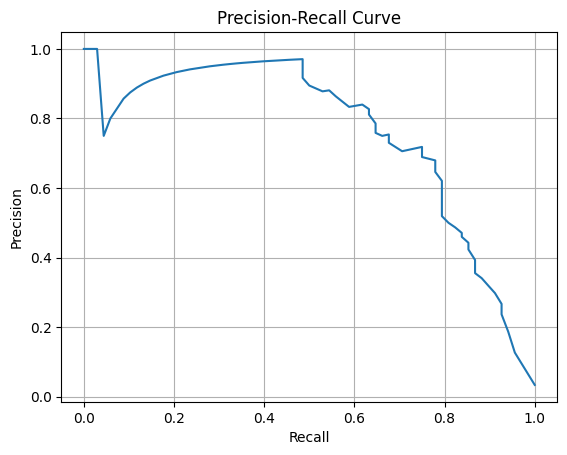

In [ ]:
# Precision - Recall Curve
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_prob)
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.97      0.46      0.62        68

    accuracy                           0.98      2000
   macro avg       0.97      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000

Confusion matrix:
 [[1931    1]
 [  37   31]]
PR-AUC (Average Precision): 0.7516943820563318


In [53]:
# Simulate incoming data drift

reference_data = X_train.copy()
incoming_data = X_test.copy()

# Controlled stress test: artificially increase torque by 15%.
incoming_data["Torque [Nm]"] = incoming_data["Torque [Nm]"] * 1.15

print("Reference shape:", reference_data.shape)
print("Incoming shape:", incoming_data.shape)


Reference shape: (8000, 6)
Incoming shape: (2000, 6)


In [54]:
# Detect numerical feature drift using the KS test

from scipy.stats import ks_2samp

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Bonferroni correction: alpha divided by number of feature tests.
alpha = 0.05
adjusted_alpha = alpha / len(numerical_features)
drift_results = []

for feature in numerical_features:
    statistic, p_value = ks_2samp(reference_data[feature], incoming_data[feature])
    reference_mean = reference_data[feature].mean()
    incoming_mean = incoming_data[feature].mean()
    mean_change_pct = (
        abs(incoming_mean - reference_mean) / abs(reference_mean) * 100
        if reference_mean != 0 else np.nan
    )
    drift_results.append({
        "Feature": feature,
        "Reference Mean": reference_mean,
        "Incoming Mean": incoming_mean,
        "Mean Change (%)": mean_change_pct,
        "KS Statistic": statistic,
        "P-value": p_value,
        "Adjusted P-value": min(p_value * len(numerical_features), 1.0),
        "Drift Detected": p_value < adjusted_alpha
    })

drift_report = pd.DataFrame(drift_results)
display(drift_report.round(4))


,Feature,Reference Mean,Incoming Mean,Mean Change (%),KS Statistic,P-value,Adjusted P-value,Drift Detected
0,Air temperature [K],300.0054,300.0028,0.0009,0.0098,0.9979,1.0,False
1,Process temperature [K],310.0061,310.0035,0.0008,0.0181,0.6652,1.0,False
2,Rotational speed [rpm],1539.3569,1536.4530,0.1886,0.0166,0.7645,1.0,False
3,Torque [Nm],40.0034,45.9093,14.7635,0.2332,0.0000,0.0,True
4,Tool wear [min],107.6850,109.0150,1.2351,0.0265,0.2089,1.0,False


In [55]:
# Create a reusable prediction function

THRESHOLD = 0.25  # Experimental threshold; validate before operational use.


def predict_machine_failure(incoming_data, preprocessor, model, threshold=THRESHOLD):
    required_features = [
        "Type", "Air temperature [K]", "Process temperature [K]",
        "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
    ]
    missing = [feature for feature in required_features if feature not in incoming_data.columns]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    processed = preprocessor.transform(incoming_data[required_features])
    probabilities = model.predict_proba(processed)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    results = incoming_data.copy()
    results["Failure Probability"] = probabilities
    results["Predicted Failure"] = predictions
    return results


def create_monitoring_summary(prediction_results):
    total = len(prediction_results)
    failures = int(prediction_results["Predicted Failure"].sum())
    normal = total - failures
    rate = failures / total * 100 if total else 0.0

    return pd.DataFrame([{
        "Total Readings": total,
        "Predicted Failures": failures,
        "Predicted Normal": normal,
        "Failure Prediction Rate (%)": round(rate, 2)
    }])


In [56]:
# Test the prediction function on the drifted batch 
prediction_results = predict_machine_failure(
    incoming_data=incoming_data,
    preprocessor=preprocessor,
    model=model,
    threshold=THRESHOLD
)

display(prediction_results.head(10))
display(create_monitoring_summary(prediction_results))


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Probability,Predicted Failure
2997,L,300.5,309.8,1345,72.105,153,0.53,1
4871,L,303.7,312.4,1513,46.115,135,0.03,0
3858,L,302.5,311.4,1559,43.240,209,0.02,0
951,H,295.6,306.3,1509,41.170,60,0.00,0
6463,H,300.5,310.0,1358,69.460,102,0.46,1
3264,H,301.3,310.1,1455,50.715,188,0.00,0
4508,L,302.4,310.0,1426,53.590,102,0.03,0
2100,M,299.3,309.3,1471,52.900,42,0.01,0
7885,L,300.7,312.3,1590,41.745,93,0.00,0
2421,L,298.9,308.2,2384,17.250,19,0.01,0


,Total Readings,Predicted Failures,Predicted Normal,Failure Prediction Rate (%)
0,2000,211,1789,10.55


In [58]:
# Evaluate predictions on the artificially drifted test batch

from sklearn.metrics import classification_report, confusion_matrix

incoming_predictions = prediction_results["Predicted Failure"].to_numpy()
print("Confusion matrix:\n", confusion_matrix(y_test, incoming_predictions))
print(classification_report(y_test, incoming_predictions, zero_division=0))


Confusion matrix:
 [[1777  155]
 [  12   56]]
              precision    recall  f1-score   support

           0       0.99      0.92      0.96      1932
           1       0.27      0.82      0.40        68

    accuracy                           0.92      2000
   macro avg       0.63      0.87      0.68      2000
weighted avg       0.97      0.92      0.94      2000



In [59]:
# Save and reload the trained model and preprocessor 

import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "failure_prediction_model.pkl"
PREPROCESSOR_PATH = MODEL_DIR / "preprocessor.pkl"

joblib.dump(model, MODEL_PATH)
joblib.dump(preprocessor, PREPROCESSOR_PATH)

print("Saved model:", MODEL_PATH.resolve())
print("Saved preprocessor:", PREPROCESSOR_PATH.resolve())


Saved model: C:\Users\Uppara Uday Sagar\ml-model-failure-warning\models\failure_prediction_model.pkl
Saved preprocessor: C:\Users\Uppara Uday Sagar\ml-model-failure-warning\models\preprocessor.pkl


In [60]:
loaded_model = joblib.load(MODEL_PATH)
loaded_preprocessor = joblib.load(PREPROCESSOR_PATH)

loaded_processed = loaded_preprocessor.transform(X_test)
loaded_probabilities = loaded_model.predict_proba(loaded_processed)[:, 1]
loaded_predictions = (loaded_probabilities >= THRESHOLD).astype(int)

original_predictions = (
    model.predict_proba(preprocessor.transform(X_test))[:, 1] >= THRESHOLD
).astype(int)

print("Predictions match:", np.array_equal(original_predictions, loaded_predictions))
print("Predicted failures:", int(loaded_predictions.sum()))
print("Predicted normal:", int((loaded_predictions == 0).sum()))


Predictions match: True
Predicted failures: 74
Predicted normal: 1926


Notes and limitations
- The selected threshold of 0.25 is experimental, not a production recommendation.
- Threshold tuning on the test set is exploratory; a validation set should be used for threshold selection.
- The drifted batch is created by modifying test data and is not live machine telemetry.
- A drift alert indicates a distribution change, not necessarily worse model performance or a confirmed failure.
- Only load Joblib files from trusted sources.